In [14]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



df = pd.read_csv(
    "/multiTimeline.csv",
    skiprows=1
)



print(df.head(10))
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

         Week  Electric vehicle: (India)
0  2021-10-10                         75
1  2021-10-17                         72
2  2021-10-24                         73
3  2021-10-31                         62
4  2021-11-07                         75
5  2021-11-14                         70
6  2021-11-21                         70
7  2021-11-28                         65
8  2021-12-05                         70
9  2021-12-12                         67
Dataset shape: (262, 2)
Column names: ['Week', 'Electric vehicle: (India)']


In [15]:

# Rename the columns
df = df.rename(columns={
    "Week": "week",
    "Electric vehicle: (India)": "search_interest"
})

# Convert the week column into a proper date
df["week"] = pd.to_datetime(df["week"])

# Check whether search-interest values are numeric
df["search_interest"] = pd.to_numeric(
    df["search_interest"],
    errors="coerce"
)

# Check the dataset
print(df.head())
print(df.info())

        week  search_interest
0 2021-10-10               75
1 2021-10-17               72
2 2021-10-24               73
3 2021-10-31               62
4 2021-11-07               75
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   week             262 non-null    datetime64[ns]
 1   search_interest  262 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 4.2 KB
None


In [16]:

print("Number of rows:", len(df))

print("Missing values:")
print(df.isnull().sum())

print("Duplicate weeks:", df["week"].duplicated().sum())

print("Minimum search interest:", df["search_interest"].min())
print("Maximum search interest:", df["search_interest"].max())

Number of rows: 262
Missing values:
week               0
search_interest    0
dtype: int64
Duplicate weeks: 0
Minimum search interest: 44
Maximum search interest: 100


In [17]:

average_interest = df["search_interest"].mean()

highest_week = df.loc[
    df["search_interest"].idxmax()
]

lowest_week = df.loc[
    df["search_interest"].idxmin()
]

print("Average search interest:", round(average_interest, 2))

print("Highest-interest week:")
print(highest_week)

print("Lowest-interest week:")
print(lowest_week)

Average search interest: 66.47
Highest-interest week:
week               2022-03-06 00:00:00
search_interest                    100
Name: 21, dtype: object
Lowest-interest week:
week               2025-10-19 00:00:00
search_interest                     44
Name: 210, dtype: object


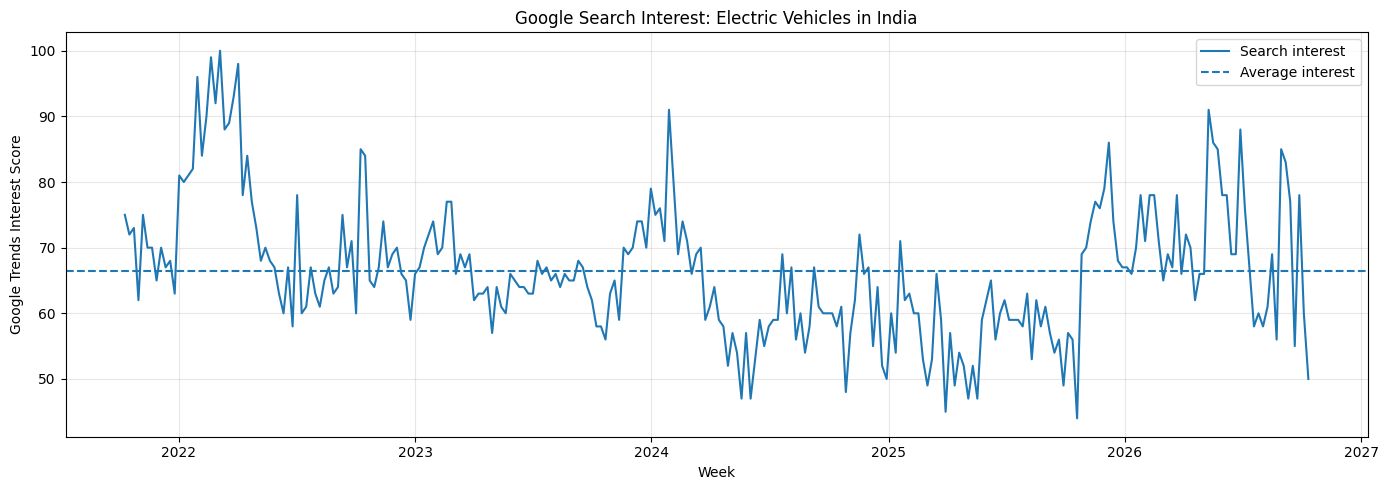

In [18]:

plt.figure(figsize=(14, 5))

plt.plot(
    df["week"],
    df["search_interest"],
    label="Search interest"
)

plt.axhline(
    df["search_interest"].mean(),
    linestyle="--",
    label="Average interest"
)

plt.title("Google Search Interest: Electric Vehicles in India")
plt.xlabel("Week")
plt.ylabel("Google Trends Interest Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:

# Extract the year from each date
df["year"] = df["week"].dt.year

# Calculate average search interest for each year
yearly_interest = (
    df.groupby("year")["search_interest"]
    .mean()
    .round(2)
)

print(yearly_interest)

year
2021    69.17
2022    73.90
2023    66.23
2024    61.81
2025    60.04
2026    70.66
Name: search_interest, dtype: float64


In [20]:

yearly_change = yearly_interest.pct_change() * 100

yearly_summary = pd.DataFrame({
    "Average Interest": yearly_interest,
    "Change (%)": yearly_change.round(2)
})

print(yearly_summary)

      Average Interest  Change (%)
year                              
2021             69.17         NaN
2022             73.90        6.84
2023             66.23      -10.38
2024             61.81       -6.67
2025             60.04       -2.86
2026             70.66       17.69


In [21]:

# Create a month column from the week date
df["month"] = df["week"].dt.month

# Calculate average search interest for each month
monthly_interest = (
    df.groupby("month")["search_interest"]
    .mean()
    .round(2)
)

print(monthly_interest)

month
1     73.18
2     74.30
3     68.83
4     64.81
5     64.68
6     62.95
7     63.68
8     62.73
9     64.57
10    62.50
11    69.19
12    67.18
Name: search_interest, dtype: float64


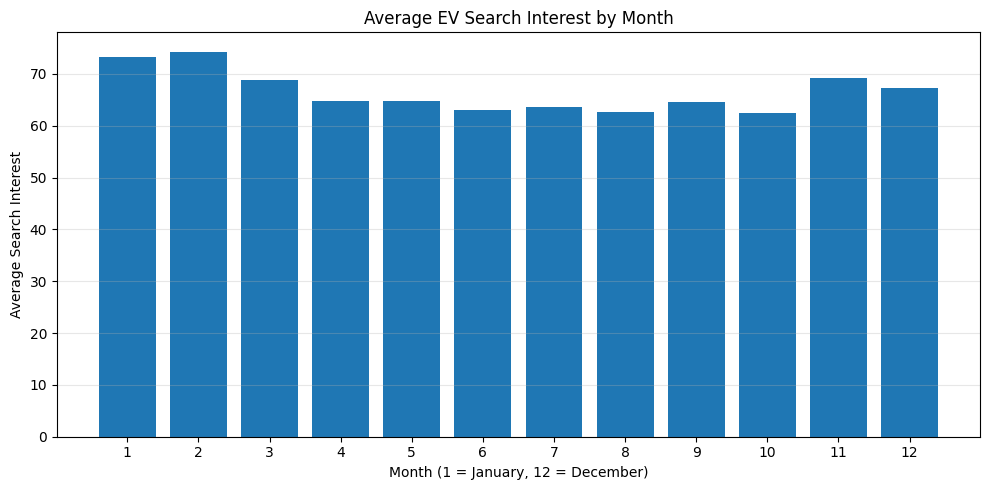

In [22]:

plt.figure(figsize=(10, 5))

plt.bar(
    monthly_interest.index,
    monthly_interest.values
)

plt.title("Average EV Search Interest by Month")
plt.xlabel("Month (1 = January, 12 = December)")
plt.ylabel("Average Search Interest")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:

highest_month = monthly_interest.idxmax()
lowest_month = monthly_interest.idxmin()

month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

print(
    "Highest-interest month:",
    month_names[highest_month],
    monthly_interest.max()
)

print(
    "Lowest-interest month:",
    month_names[lowest_month],
    monthly_interest.min()
)

Highest-interest month: February 74.3
Lowest-interest month: October 62.5


In [24]:

top_5_weeks = df.nlargest(
    5,
    "search_interest"
)[["week", "search_interest"]]

print(top_5_weeks)

         week  search_interest
21 2022-03-06              100
19 2022-02-20               99
25 2022-04-03               98
16 2022-01-30               96
24 2022-03-27               93


In [25]:

bottom_5_weeks = df.nsmallest(
    5,
    "search_interest"
)[["week", "search_interest"]]

print(bottom_5_weeks)

          week  search_interest
210 2025-10-19               44
181 2025-03-30               45
136 2024-05-19               47
138 2024-06-02               47
186 2025-05-04               47


In [26]:
#Check whether the peak was an isolated event or part of a wider pattern
top_20_weeks = df.nlargest(20, "search_interest")

peak_year_counts = top_20_weeks["year"].value_counts().sort_index()

print("Top 20 weeks by year:")
print(peak_year_counts)

Top 20 weeks by year:
year
2022    13
2024     1
2025     1
2026     5
Name: count, dtype: int64


In [27]:

complete_years = df[
    df["week"].dt.year.isin([2022, 2023, 2024, 2025])
]

yearly_comparison = (
    complete_years.groupby("year")["search_interest"]
    .mean()
    .round(2)
)

print("Comparable full-year averages:")
print(yearly_comparison)

Comparable full-year averages:
year
2022    73.90
2023    66.23
2024    61.81
2025    60.04
Name: search_interest, dtype: float64


In [28]:

# Compare monthly averages across complete years
seasonality = complete_years.copy()

seasonality["month"] = seasonality["week"].dt.month

monthly_by_year = seasonality.pivot_table(
    index="month",
    columns="year",
    values="search_interest",
    aggfunc="mean"
).round(2)

print(monthly_by_year.loc[[2, 10]])

year    2022   2023   2024  2025
month                           
2      91.25  73.25  73.50  59.0
10     71.60  59.40  56.75  56.5


In [29]:

monthly_comparison = monthly_by_year.loc[[2, 10]].T.copy()

monthly_comparison.columns = [
    "February",
    "October"
]

monthly_comparison["Difference"] = (
    monthly_comparison["February"]
    - monthly_comparison["October"]
)

monthly_comparison["February vs October (%)"] = (
    monthly_comparison["Difference"]
    / monthly_comparison["October"]
    * 100
).round(2)

print(monthly_comparison.round(2))

      February  October  Difference  February vs October (%)
year                                                        
2022     91.25    71.60       19.65                    27.44
2023     73.25    59.40       13.85                    23.32
2024     73.50    56.75       16.75                    29.52
2025     59.00    56.50        2.50                     4.42


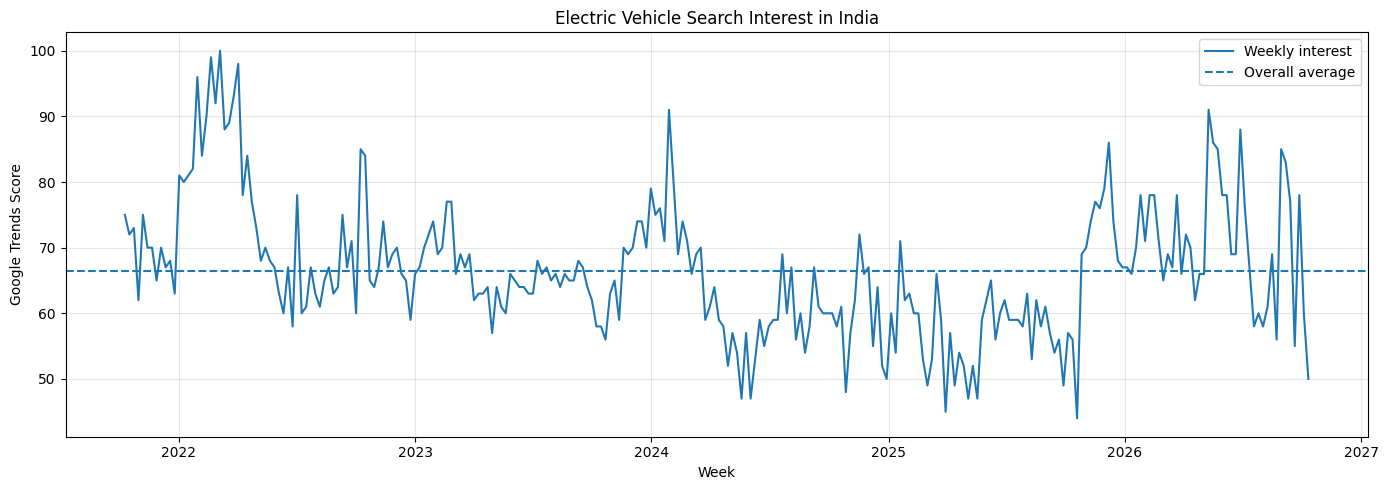

In [30]:
#Overall search-interest trend
plt.figure(figsize=(14, 5))

plt.plot(
    df["week"],
    df["search_interest"],
    label="Weekly interest"
)

plt.axhline(
    df["search_interest"].mean(),
    linestyle="--",
    label="Overall average"
)

plt.title("Electric Vehicle Search Interest in India")
plt.xlabel("Week")
plt.ylabel("Google Trends Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("01_overall_trend.png", dpi=150, bbox_inches="tight")
plt.show()

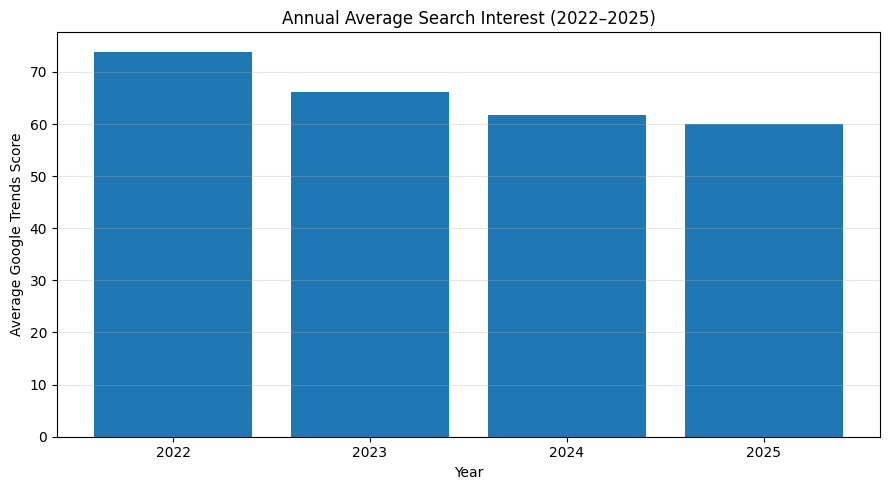

In [31]:
#Full year
plt.figure(figsize=(9, 5))

plt.bar(
    yearly_comparison.index.astype(str),
    yearly_comparison.values
)

plt.title("Annual Average Search Interest (2022–2025)")
plt.xlabel("Year")
plt.ylabel("Average Google Trends Score")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("02_annual_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

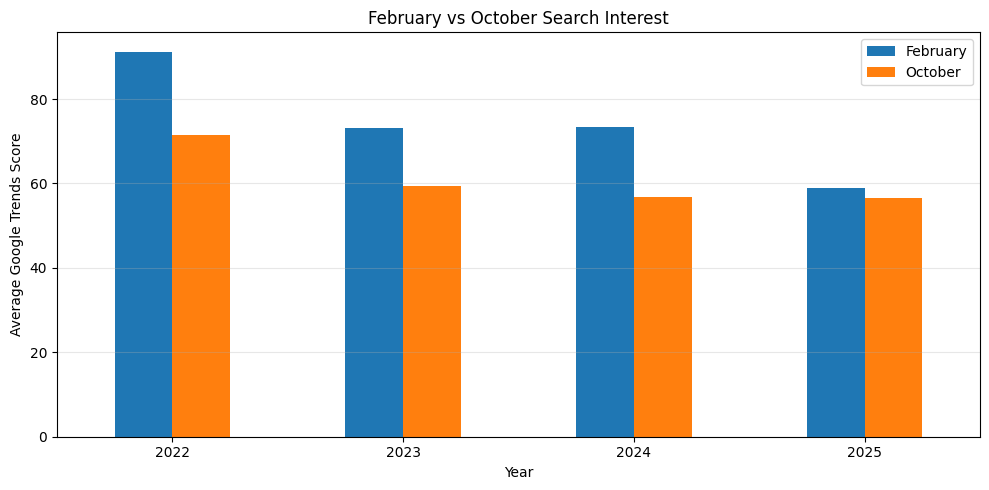

In [32]:

monthly_comparison[["February", "October"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("February vs October Search Interest")
plt.xlabel("Year")
plt.ylabel("Average Google Trends Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("03_monthly_comparison.png", dpi=150, bbox_inches="tight")
plt.show()